In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logit, expit
from sklearn.feature_selection import mutual_info_regression

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')
RANDOM_STATE = 42

In [2]:
train = pd.read_parquet('/content/train.parquet')
test  = pd.read_parquet('/content/test_template.parquet')

print("Train shape:", train.shape)
print("Test  shape:", test.shape)
print("\nКолонки train:", train.columns.tolist())
print("Колонки test :", test.columns.tolist())

print("\nТипы train:")
print(train.dtypes.value_counts())

Train shape: (321531, 25)
Test  shape: (31586, 24)

Колонки train: ['store_pseudo_id', 'week', 'target', 'feature1', 'feature3', 'feature4', 'feature5', 'feature6', 'feature7', 'feature8', 'feature9', 'feature10', 'feature14', 'feature16', 'feature17', 'feature18', 'feature19', 'feature20', 'feature21', 'feature22', 'feature23', 'feature24', 'feature25', 'feature26', 'feature28']
Колонки test : ['store_pseudo_id', 'week', 'feature1', 'feature3', 'feature4', 'feature5', 'feature6', 'feature7', 'feature8', 'feature9', 'feature10', 'feature14', 'feature16', 'feature17', 'feature18', 'feature19', 'feature20', 'feature21', 'feature22', 'feature23', 'feature24', 'feature25', 'feature26', 'feature28']

Типы train:
int64      12
object      7
float64     6
Name: count, dtype: int64


In [3]:
# Convert the 'week' column to datetime in both dataframes
for df in (train, test):
    df['week'] = pd.to_datetime(df['week'])
    # Extract calendar components from the datetime column
    df['year']    = df['week'].dt.year
    df['month']   = df['week'].dt.month
    df['woy']     = df['week'].dt.isocalendar().week.astype(int)
    df['quarter'] = df['week'].dt.quarter

# Check the time ranges of both splits to confirm the temporal order
print("Train period:", train['week'].min(), "—", train['week'].max())
print("Test  period:", test['week'].min(),  "—", test['week'].max())

# Count unique weeks to understand the panel frequency
print("Train unique weeks:", train['week'].nunique())
print("Test  unique weeks:", test['week'].nunique())

Train period: 2023-07-10 00:00:00 — 2026-05-04 00:00:00
Test  period: 2026-05-11 00:00:00 — 2026-07-06 00:00:00
Train unique weeks: 148
Test  unique weeks: 9


In [4]:
# Build a side-by-side missing-value report for train and test
miss = pd.DataFrame({
    'train_na_%': train.isna().mean() * 100,
    'test_na_%':  test.isna().mean()  * 100,
})
# Difference in percentage points highlights drift in missingness
miss['diff_pp'] = miss['test_na_%'] - miss['train_na_%']
print(miss.sort_values('train_na_%', ascending=False).round(3))

                 train_na_%  test_na_%  diff_pp
feature26            76.412     77.826    1.414
feature24            36.288     33.895   -2.393
feature9              9.328      9.558    0.230
feature10             1.942      2.397    0.455
feature8              1.942      2.397    0.455
feature17             0.000      0.000    0.000
feature18             0.000      0.000    0.000
feature20             0.000      0.000    0.000
feature19             0.000      0.000    0.000
feature21             0.000      0.000    0.000
feature1              0.000      0.000    0.000
feature16             0.000      0.000    0.000
feature14             0.000      0.000    0.000
feature25             0.000      0.000    0.000
feature23             0.000      0.000    0.000
feature22             0.000      0.000    0.000
feature3              0.000      0.000    0.000
feature4              0.000      0.000    0.000
feature5              0.000      0.000    0.000
feature6              0.000      0.000  

In [5]:
target_col = 'target'
# Columns that should not be treated as model features
ignore_cols = [target_col, 'store_pseudo_id', 'week', 'year', 'month', 'woy', 'quarter']

# Categorical: object dtype or low cardinality (< 20 unique values)
cat_cols = [c for c in train.columns
            if c not in ignore_cols
            and (train[c].dtype == 'object' or train[c].nunique(dropna=True) < 20)]

# Numeric: everything else that is not in the ignore list
num_cols = [c for c in train.columns
            if c not in cat_cols + ignore_cols]

print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['feature1', 'feature3', 'feature4', 'feature5', 'feature8', 'feature9', 'feature16', 'feature17', 'feature19', 'feature20', 'feature21', 'feature24', 'feature26', 'feature28']
Numeric: ['feature6', 'feature7', 'feature10', 'feature14', 'feature18', 'feature22', 'feature23', 'feature25']


count    321531.000000
mean          0.252032
std           0.107258
min           0.000000
25%           0.174209
50%           0.234502
75%           0.311850
max           1.000000
Name: target, dtype: float64

Skew: 1.0306545188776037  Kurt: 1.6871767486147946
Share exactly 0: 3.110120019531554e-06
Share exactly 1: 3.110120019531554e-06
Share in [0, 0.05]: 0.0009361461258789977
Share in [0.95, 1]: 1.2440480078126215e-05


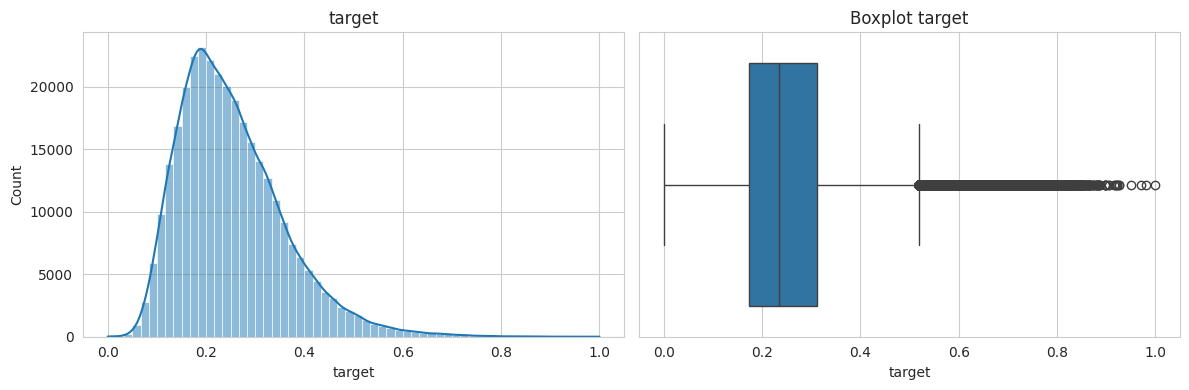

In [6]:
t = train[target_col]

# Basic distribution statistics
print(t.describe())
print("\nSkew:", t.skew(), " Kurt:", t.kurt())

# Check how much mass sits exactly at the boundaries and near them
print("Share exactly 0:", (t == 0).mean())
print("Share exactly 1:", (t == 1).mean())
print("Share in [0, 0.05]:", (t <= 0.05).mean())
print("Share in [0.95, 1]:", (t >= 0.95).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(t, bins=60, kde=True, ax=axes[0]); axes[0].set_title('target')
sns.boxplot(x=t, ax=axes[1]); axes[1].set_title('Boxplot target')
plt.tight_layout(); plt.show()

Skew logit: 0.2338971197922863 Kurt: 3.3105078651586406


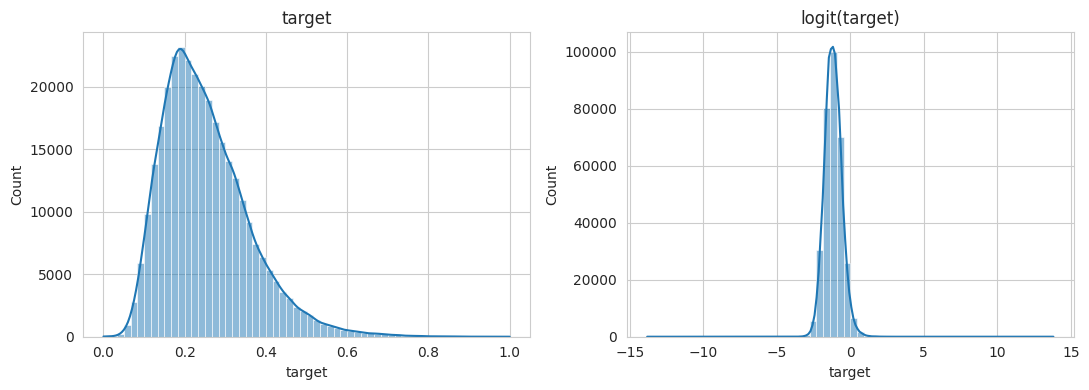

In [7]:
# Clip to avoid infinities at 0 and 1 before applying logit
eps = 1e-6
lt = logit(t.clip(eps, 1 - eps))
print("Skew logit:", lt.skew(), "Kurt:", lt.kurt())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(t, bins=60, kde=True, ax=ax[0]); ax[0].set_title('target')
sns.histplot(lt, bins=60, kde=True, ax=ax[1]); ax[1].set_title('logit(target)')
plt.tight_layout(); plt.show()

In [8]:
def cat_compare(col, top_n=15):
    # Share of each category in train and test
    tr = train[col].value_counts(normalize=True).rename('train_share')
    te = test[col].value_counts(normalize=True).rename('test_share')
    cmp = pd.concat([tr, te], axis=1).fillna(0)
    # Positive diff => category is more frequent in train
    cmp['diff'] = cmp['train_share'] - cmp['test_share']
    return cmp.sort_values('train_share', ascending=False).head(top_n)

for col in cat_cols:
    print(f"\n=== {col} ===")
    print(cat_compare(col).round(5))


=== feature1 ===
          train_share  test_share     diff
feature1                                  
OPND          0.97417     0.99576 -0.02159
CLSD          0.02006     0.00082  0.01924
RECS          0.00577     0.00342  0.00235

=== feature3 ===
          train_share  test_share     diff
feature3                                  
ter_3         0.23308     0.20249  0.03058
ter_6         0.05618     0.05081  0.00537
ter_15        0.05311     0.06601 -0.01290
ter_8         0.05205     0.04904  0.00301
ter_7         0.04851     0.05999 -0.01148
ter_4         0.04845     0.03824  0.01020
ter_19        0.04522     0.03945  0.00577
ter_17        0.04220     0.04391 -0.00171
ter_11        0.03521     0.03739 -0.00218
ter_5         0.03504     0.03302  0.00202
ter_13        0.02786     0.03055 -0.00269
ter_2         0.02701     0.02913 -0.00212
ter_12        0.02515     0.03289 -0.00775
ter_1         0.02500     0.02957 -0.00457
ter_9         0.02429     0.02485 -0.00056

=== feature4 ===


In [9]:
summary = []
for col in cat_cols:
    # Set difference: values present in test but unseen in train
    tr_vals = set(train[col].dropna().unique())
    te_vals = set(test[col].dropna().unique())
    only_test = te_vals - tr_vals
    summary.append({
        'col': col,
        'train_nunique': len(tr_vals),
        'test_nunique':  len(te_vals),
        'n_new_in_test': len(only_test),
        'new_values': sorted(list(only_test))[:5]
    })
print(pd.DataFrame(summary).to_string(index=False))

      col  train_nunique  test_nunique  n_new_in_test                                                                       new_values
 feature1              3             3              0                                                                               []
 feature3             49            49              0                                                                               []
 feature4              2             2              0                                                                               []
 feature5              2             2              0                                                                               []
 feature8            217           223              7 [competitor_148, competitor_211, competitor_217, competitor_218, competitor_220]
 feature9              4             4              0                                                                               []
feature16              1             1              0  

In [10]:
# Describe numeric features and compare train vs test means
num_summary = train[num_cols].describe().T
num_summary['test_mean'] = test[num_cols].mean()
num_summary['test_std']  = test[num_cols].std()
# Relative mean shift in percent
num_summary['mean_diff_%'] = (num_summary['test_mean'] - num_summary['mean']) / num_summary['mean'] * 100
print(num_summary.round(3))

              count     mean      std    min     25%     50%     75%     max  test_mean  test_std  mean_diff_%
feature6   321531.0  293.178   38.306    9.0  276.00  289.00  305.00  1916.0    290.878    37.480       -0.785
feature7   321531.0  402.799   57.536  297.0  376.00  395.00  419.00  2436.0    397.400    54.121       -1.340
feature10  315288.0  101.155   91.813    0.0   33.00   77.00  140.00   499.0    102.072    93.395        0.907
feature14  321531.0  501.035  349.825    0.0  213.00  446.00  738.00  2013.0    715.676   431.159       42.840
feature18  321531.0   25.590   15.614    1.0   12.00   25.00   40.00    52.0     24.036     2.584       -6.071
feature22  321531.0    0.085    0.687   -1.0   -0.56    0.13    0.75     1.0     -0.888     0.115    -1149.756
feature23  321531.0    0.044    0.721   -1.0   -0.67    0.08    0.80     1.0      0.342     0.282      681.742
feature25  321531.0   36.769   47.250  -10.0   -1.00    8.00   99.00    99.0     33.761    46.958       -8.181


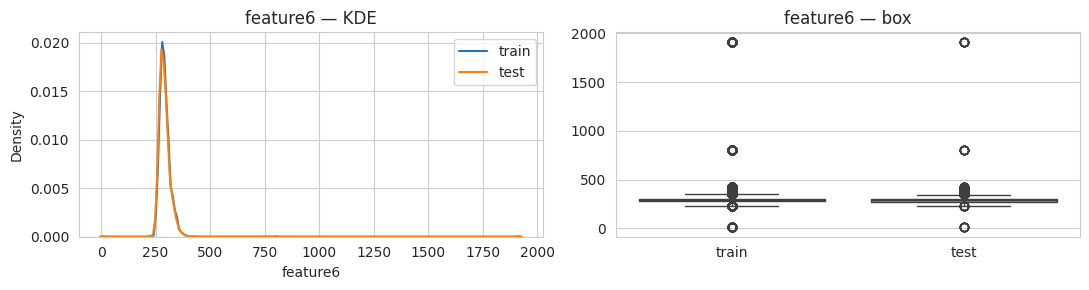

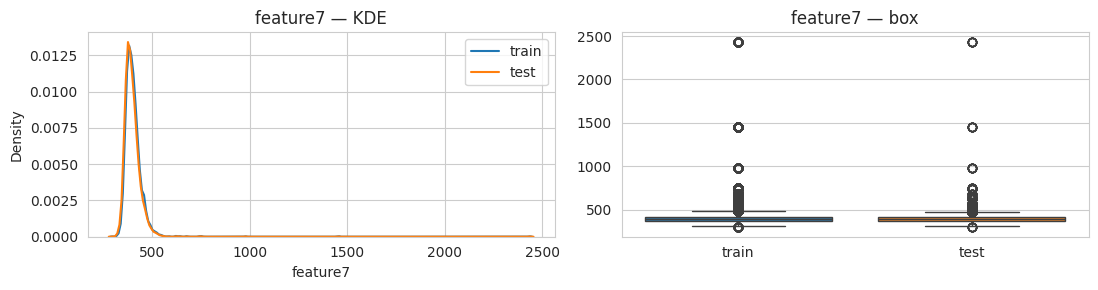

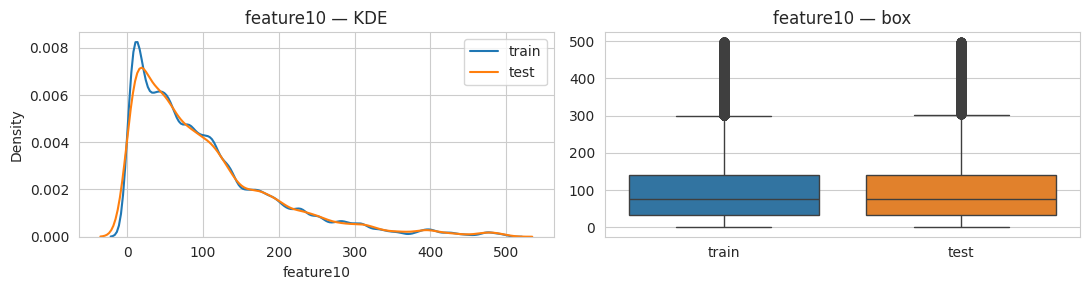

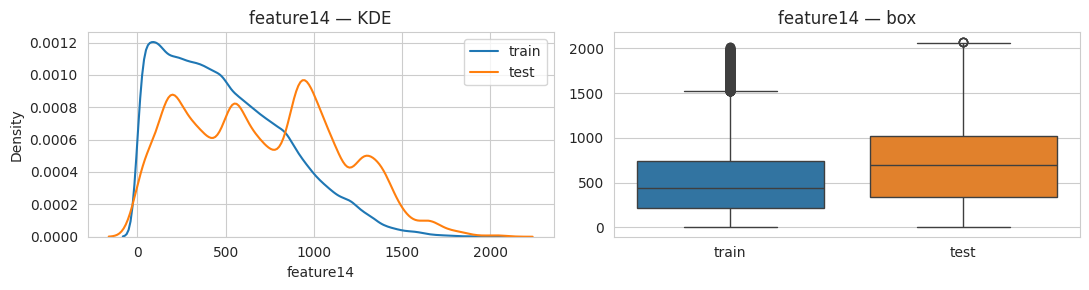

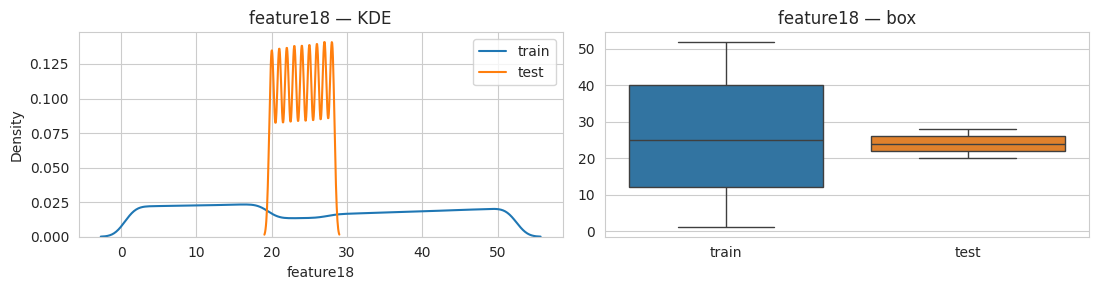

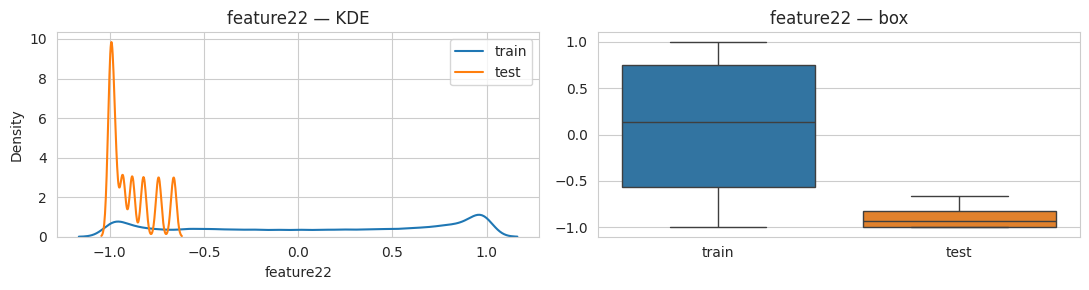

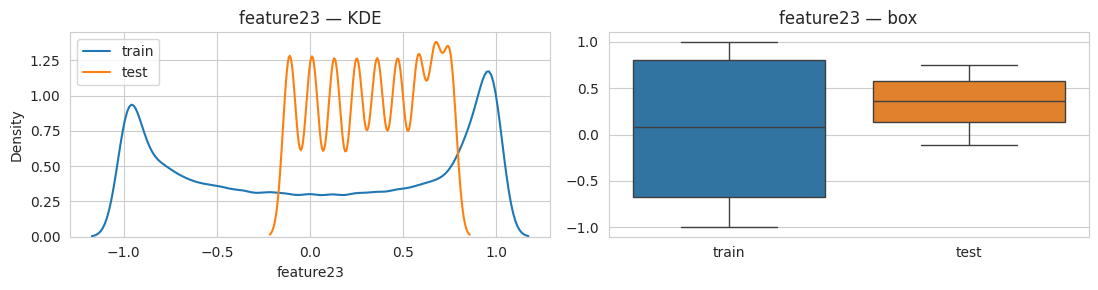

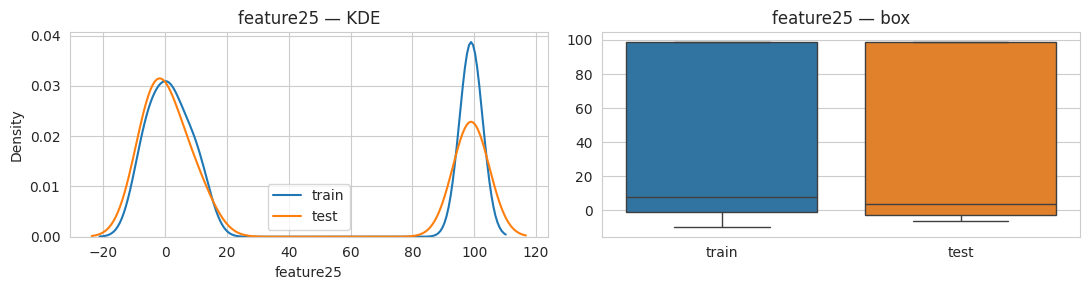

In [11]:
# Compare distributions visually for each numeric feature
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    sns.kdeplot(train[col].dropna(), label='train', ax=ax[0])
    sns.kdeplot(test[col].dropna(),  label='test',  ax=ax[0])
    ax[0].set_title(f'{col} — KDE'); ax[0].legend()
    sns.boxplot(data=pd.DataFrame({'train': train[col], 'test': test[col]}), ax=ax[1])
    ax[1].set_title(f'{col} — box')
    plt.tight_layout(); plt.show()

In [12]:
# Aggregate target statistics per category to spot predictive levels
for col in cat_cols:
    g = (train.groupby(col, dropna=False)[target_col]
              .agg(['mean', 'median', 'count'])
              .sort_values('mean', ascending=False))
    print(f"\n=== {col} ===")
    print(g.head(15).round(4))


=== feature1 ===
            mean  median   count
feature1                        
RECS      0.3338  0.3021    1854
OPND      0.2527  0.2353  313226
CLSD      0.1973  0.1488    6451

=== feature3 ===
            mean  median  count
feature3                       
ter_45    0.4035  0.4222    236
ter_3     0.3226  0.3099  74941
ter_31    0.2959  0.2789   4439
ter_21    0.2871  0.2735   4359
ter_18    0.2851  0.2750    602
ter_25    0.2785  0.2727   5043
ter_47    0.2757  0.2882    253
ter_34    0.2730  0.2828   3749
ter_20    0.2705  0.2497   4170
ter_38    0.2691  0.2684   1689
ter_9     0.2690  0.2604   7811
ter_8     0.2629  0.2488  16737
ter_32    0.2613  0.2501    143
ter_12    0.2569  0.2475   8085
ter_36    0.2568  0.2467   1387

=== feature4 ===
            mean  median   count
feature4                        
1         0.2522  0.2354  289681
0         0.2502  0.2250   31850

=== feature5 ===
            mean  median   count
feature5                        
0         0.3204  0.2

In [13]:
# Pearson correlation of each numeric feature with target
corr = (train[num_cols + [target_col]]
        .corr(numeric_only=True)[target_col]
        .sort_values(ascending=False))
print("Pearson correlation with target:\n", corr.round(4))

# Mutual information captures non-linear dependencies
mi = mutual_info_regression(
    train[num_cols].fillna(train[num_cols].median()),
    train[target_col], random_state=RANDOM_STATE)
print("\nMutual info:\n",
      pd.Series(mi, index=num_cols).sort_values(ascending=False).round(4))

Pearson correlation with target:
 target       1.0000
feature14    0.5178
feature18    0.0439
feature23    0.0401
feature7     0.0389
feature25    0.0124
feature10    0.0082
feature22    0.0011
feature6    -0.0061
Name: target, dtype: float64

Mutual info:
 feature14    0.1991
feature7     0.1619
feature10    0.1508
feature6     0.1284
feature23    0.0302
feature22    0.0188
feature18    0.0132
feature25    0.0044
dtype: float64


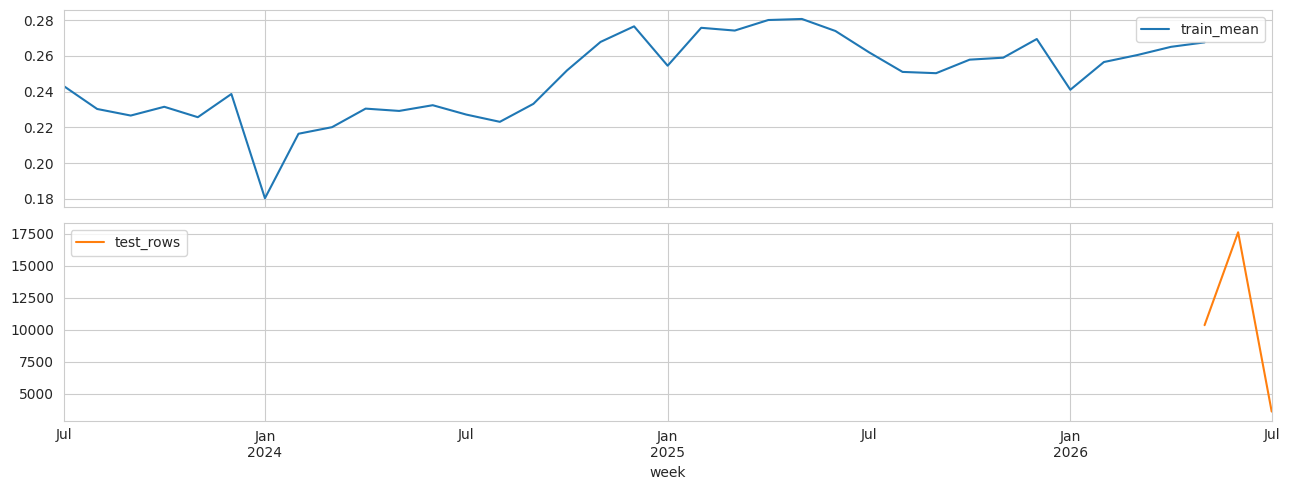

In [14]:
# Monthly average target in train and monthly row count in test
monthly = (train.groupby(train['week'].dt.to_period('M'))[target_col]
                .mean().rename('train_mean'))
monthly_test = (test.assign(dummy=0)
                    .groupby(test['week'].dt.to_period('M'))
                    .size().rename('test_rows'))
pd.concat([monthly, monthly_test], axis=1).plot(figsize=(13, 5), subplots=True)
plt.tight_layout(); plt.show()

In [15]:
# Row-level duplicates
print("Duplicate rows in train:", train.duplicated().sum())
# Unique stores and overlap between splits
print("Unique store_pseudo_id in train:", train['store_pseudo_id'].nunique())
print("Store overlap train∩test:",
      len(set(train['store_pseudo_id']) & set(test['store_pseudo_id'])))
# Panel key uniqueness
print("Duplicate (store, week) in train:",
      train.duplicated(['store_pseudo_id','week']).sum())
print("Duplicate (store, week) in test:",
      test.duplicated(['store_pseudo_id','week']).sum())

Duplicate rows in train: 0
Unique store_pseudo_id in train: 3561
Store overlap train∩test: 3438
Duplicate (store, week) in train: 0
Duplicate (store, week) in test: 0


In [16]:
def eda_report(train, test, target_col='target'):
    rep = {}
    rep['train_shape'] = train.shape
    rep['test_shape']  = test.shape
    rep['target_describe'] = train[target_col].describe().to_dict()
    rep['target_skew'] = float(train[target_col].skew())
    rep['target_kurt'] = float(train[target_col].kurt())
    # Logit skew indicates how close the transformed target is to normal
    rep['target_logit_skew'] = float(logit(train[target_col].clip(1e-6, 1 - 1e-6)).skew())
    rep['na_train_top'] = train.isna().mean().sort_values(ascending=False).head(10).to_dict()
    rep['na_test_top']  = test.isna().mean().sort_values(ascending=False).head(10).to_dict()
    # List categorical values that appear only in test
    cat_cols = [c for c in train.columns
                if train[c].dtype == 'object' and c != target_col]
    rep['cat_new_in_test'] = {
        c: sorted(set(test[c].dropna()) - set(train[c].dropna())) for c in cat_cols
    }
    rep['train_period'] = (str(train['week'].min()), str(train['week'].max()))
    rep['test_period']  = (str(test['week'].min()),  str(test['week'].max()))
    rep['n_stores_train'] = train['store_pseudo_id'].nunique()
    rep['n_stores_test']  = test['store_pseudo_id'].nunique()
    rep['store_overlap']  = len(set(train['store_pseudo_id']) & set(test['store_pseudo_id']))
    return rep

import json
print(json.dumps(eda_report(train, test), ensure_ascii=False, indent=2, default=str))

{
  "train_shape": [
    321531,
    29
  ],
  "test_shape": [
    31586,
    28
  ],
  "target_describe": {
    "count": 321531.0,
    "mean": 0.2520316616249214,
    "std": 0.10725815200924525,
    "min": 0.0,
    "25%": 0.17420885174570674,
    "50%": 0.2345016898879698,
    "75%": 0.31184972414456874,
    "max": 1.0
  },
  "target_skew": 1.0306545188776037,
  "target_kurt": 1.6871767486147946,
  "target_logit_skew": 0.2338971197922863,
  "na_train_top": {
    "feature26": 0.7641191673586684,
    "feature24": 0.3628763633988636,
    "feature9": 0.09327560950577082,
    "feature8": 0.01941647928193549,
    "feature10": 0.01941647928193549,
    "feature3": 0.0,
    "feature1": 0.0,
    "target": 0.0,
    "feature4": 0.0,
    "feature7": 0.0
  },
  "na_test_top": {
    "feature26": 0.7782561894510226,
    "feature24": 0.33894763502817704,
    "feature9": 0.09558032039511176,
    "feature8": 0.023966314189830938,
    "feature10": 0.023966314189830938,
    "feature1": 0.0,
    "feature3"

The data is a clean weekly store-level panel (321,531 × 25 train; 31,586 × 24 test) with a continuous target in [0, 1] that is right-skewed (skew 1.03) but almost normal after logit transform (skew 0.23).

No duplicates, no covariate shift in numeric features, no missingness drift — the data quality is high.

The dominant predictor is feature14 (corr 0.52, MI 0.20); feature6, feature7, feature10 carry strong non-linear signal (high MI, near-zero correlation), so tree ensembles are essential.

The main modeling risk is a strong train/test shift in several categorical features (feature17, feature19–feature24, feature26, feature28), plus 7 unseen competitor_* levels in feature8.